In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
ART = ROOT / "artifacts"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from plotting import series_styles, new_figure

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

def es(v, d=4):
    """Numero con formato de Colombia: punto de miles y coma decimal."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return ""
    if isinstance(v, (int, np.integer)):
        return f"{int(v):,}".replace(",", ".")
    s = f"{float(v):,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def tabla(df, d=4, enteros=()):
    out = df.copy()
    for c in out.columns:
        if c in enteros:
            out[c] = out[c].map(lambda v: es(int(v)) if pd.notna(v) else "")
        elif pd.api.types.is_float_dtype(out[c]):
            out[c] = out[c].map(lambda v: es(v, d))
        elif pd.api.types.is_integer_dtype(out[c]):
            out[c] = out[c].map(es)
    display(out.style.hide(axis="index"))

def figura(ruta, ancho=None):
    display(Image(filename=str(ruta), width=ancho))

# 8. Interpretabilidad

Este capítulo responde la pregunta P4: ¿son las explicaciones de LIME estables y fieles al modelo? Para responderla se explican con LIME los errores más confiados del MLP de scikit-learn, se mide la fidelidad del sustituto local, su estabilidad entre semillas y su sensibilidad al ancho del kernel y al número de muestras perturbadas, y se contrastan las explicaciones con SHAP y con la importancia por permutación {cite}`ribeiro2016should,lundberg2017unified`. El propósito no es solo describir qué variables pesan, sino establecer cuánto se puede confiar en cada método y en qué condiciones falla.

Todas las cifras de este capítulo se generan con `src/interpretability.py`; la muestra del día 30 se extrae con muestreo determinista (DuckDB con un solo hilo), así que las instancias y los resultados se reproducen al volver a correr el script.

In [2]:
import json
from matplotlib.patches import Patch
IN = ART / "interpretability"
inst = pd.read_csv(IN / "instancias_explicadas.csv", index_col=0)
lime = pd.read_csv(IN / "lime_explicaciones.csv")
stab = pd.read_csv(IN / "lime_estabilidad_jaccard.csv")
shp = pd.read_csv(IN / "shap_valores.csv")
agr = pd.read_csv(IN / "concordancia_lime_shap.csv")
perm = pd.read_csv(IN / "permutation_importance.csv")
sens = pd.read_csv(IN / "lime_sensibilidad.csv")
disq = pd.read_csv(IN / "lime_discretizacion_cuartiles.csv")
dise = pd.read_csv(IN / "lime_discretizacion_efecto.csv")
FEATS = [c for c in shp.columns if c.endswith("_freq") or c.endswith("_te")]
POS, NEG = "#4d4d4d", "#bfbfbf"
def ejes(ax, titulo):
    ax.grid(True, axis="x", color="#d9d9d9", linewidth=0.6); ax.set_axisbelow(True)
    ax.set_title(titulo, fontsize=10)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
def barras(ax, etiquetas, valores, titulo):
    y = np.arange(len(valores))[::-1]
    cols = [POS if v > 0 else NEG for v in valores]
    hat = ["" if v > 0 else "////" for v in valores]
    for yi, v, c, h in zip(y, valores, cols, hat):
        ax.barh(yi, v, color=c, hatch=h, edgecolor="#1a1a1a", linewidth=0.5, height=0.7)
    ax.set_yticks(y); ax.set_yticklabels(etiquetas, fontsize=7.5)
    ax.axvline(0, color="#1a1a1a", linewidth=0.8); ejes(ax, titulo)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
LEYENDA = [Patch(facecolor=POS, edgecolor="#1a1a1a", label="sube la probabilidad de clic"),
           Patch(facecolor=NEG, hatch="////", edgecolor="#1a1a1a", label="baja la probabilidad de clic")]

## 8.1 Modelo, instancias y espacio interpretable

El modelo explicado es el MLP de una capa oculta de 50 neuronas, entrenado con el tier mayor (1.601.694 filas) y la semilla 13, con su umbral de 0,2062 elegido en validación. Sobre una muestra de 500.000 filas del día 30 se eligen de forma sistemática, como pide el enunciado, los 6 falsos positivos con mayor probabilidad predicha y los 6 falsos negativos con menor probabilidad, es decir, los errores de mayor confianza errónea.

Con hashing, las 4.096 columnas del bloque disperso no son legibles: cada una mezcla tokens de varias variables. Por tal motivo, LIME y SHAP se aplican sobre un espacio reducido de 14 variables densas con nombre, la frecuencia (`_freq`) y el target encoding fuera de pliegue (`_te`) de las 7 columnas de alta cardinalidad, ya estandarizadas. La correspondencia con las variables originales es directa, porque cada variable del espacio reducido es función de una sola columna original: `app_id_te` es la tasa de clic suavizada de la aplicación en train, y `app_id_freq` su frecuencia relativa. El bloque hasheado de la instancia se mantiene fijo en todas las perturbaciones, de modo que lo que se explica es la función

$$g_x(\mathbf d) = f\big(\mathbf h_x,\ \mathbf d\big), \qquad \mathbf d \in \mathbb R^{14},$$

donde $\mathbf h_x$ es el bloque hasheado de la instancia $x$ y $\mathbf d$ el bloque denso perturbado. LIME busca el sustituto lineal $\hat g$ que minimiza la pérdida ponderada por cercanía {cite}`ribeiro2016should`:

$$\hat g = \arg\min_{g \in G}\ \sum_{z} \pi_x(z)\,\big(g_x(z) - g(z')\big)^2 + \Omega(g), \qquad \pi_x(z) = \sqrt{\exp\!\left(-\frac{D(x,z)^2}{\sigma^2}\right)},$$

con $\sigma = 0{,}75\sqrt{14} \approx 2{,}81$ por defecto. Como se usa `discretize_continuous=True`, cada variable se discretiza en cuartiles de la muestra de referencia y $z'$ es un vector binario que indica si la perturbación quedó en el mismo intervalo que la instancia. El peso de una condición como `app_id_te > 0.42` mide entonces el cambio de probabilidad asociado a permanecer en ese intervalo frente a salir de él.

In [3]:
t = inst.reset_index().rename(columns={"index": "instancia", "p_pred": "probabilidad predicha",
                                        "y_true": "clase real", "tipo_error": "tipo de error"})
t = t.merge(shp.rename(columns={"indice_instancia": "instancia"})[["instancia", "valor_base"]], on="instancia")
tabla(t.rename(columns={"valor_base": "valor base SHAP"}), d=4, enteros=("instancia", "clase real"))

instancia,probabilidad predicha,clase real,tipo de error,valor base SHAP
162.046,"0,9437",0,FP,"0,2201"
425.036,"0,9205",0,FP,"0,2212"
20.447,"0,9075",0,FP,"0,2606"
108.238,"0,9075",0,FP,"0,2606"
293.206,"0,8996",0,FP,"0,2519"
222.511,"0,8914",0,FP,"0,2452"
421.018,"0,0031",1,FN,"0,1023"
357.301,"0,0057",1,FN,"0,1281"
316.607,"0,0062",1,FN,"0,0905"
33.350,"0,0063",1,FN,"0,0986"


**Interpretación.** Los falsos positivos tienen probabilidades predichas entre 0,891 y 0,944 sin haber recibido clic, y los falsos negativos entre 0,0031 y 0,0066 a pesar de haberlo recibido. Dos falsos positivos, el 20447 y el 108238, tienen la misma probabilidad (0,9075) y explicaciones idénticas, porque comparten el mismo perfil en todas las columnas. El valor base de SHAP no es igual para todas las instancias: va de 0,220 a 0,261 en los falsos positivos y de 0,091 a 0,153 en los falsos negativos.

Esto significa que el bloque hasheado ya mueve la probabilidad antes de que intervengan las 14 variables explicadas. El valor base es $\mathbb E_{\mathbf d}[f(\mathbf h_x, \mathbf d)]$, la predicción media cuando el bloque denso se toma del fondo y el hasheado se deja en el de la instancia. En los falsos negativos ese valor ronda 0,12, por debajo de la tasa base de 0,17, así que una parte de la probabilidad baja de esas impresiones se debe a variables de baja cardinalidad y al cruce `site_id × device_type`, que no se explican aquí. Las variables densas explican, en promedio, la distancia entre ese valor base y la predicción: suben la probabilidad unos 0,67 puntos en los falsos positivos y la bajan unos 0,11 en los falsos negativos.

Por ello, se recomienda leer las explicaciones de este capítulo como explicaciones condicionales al bloque hasheado y no como una atribución completa de la predicción. Es la limitación que impone el hashing y la razón por la que el enunciado pide documentar la correspondencia con las variables originales.

## 8.2 Explicaciones locales

La figura compara, para el falso positivo y el falso negativo más confiados, las 8 condiciones de LIME con la semilla 13 y los 8 valores SHAP de mayor magnitud. Las barras oscuras suben la probabilidad de clic y las claras con trama la bajan.

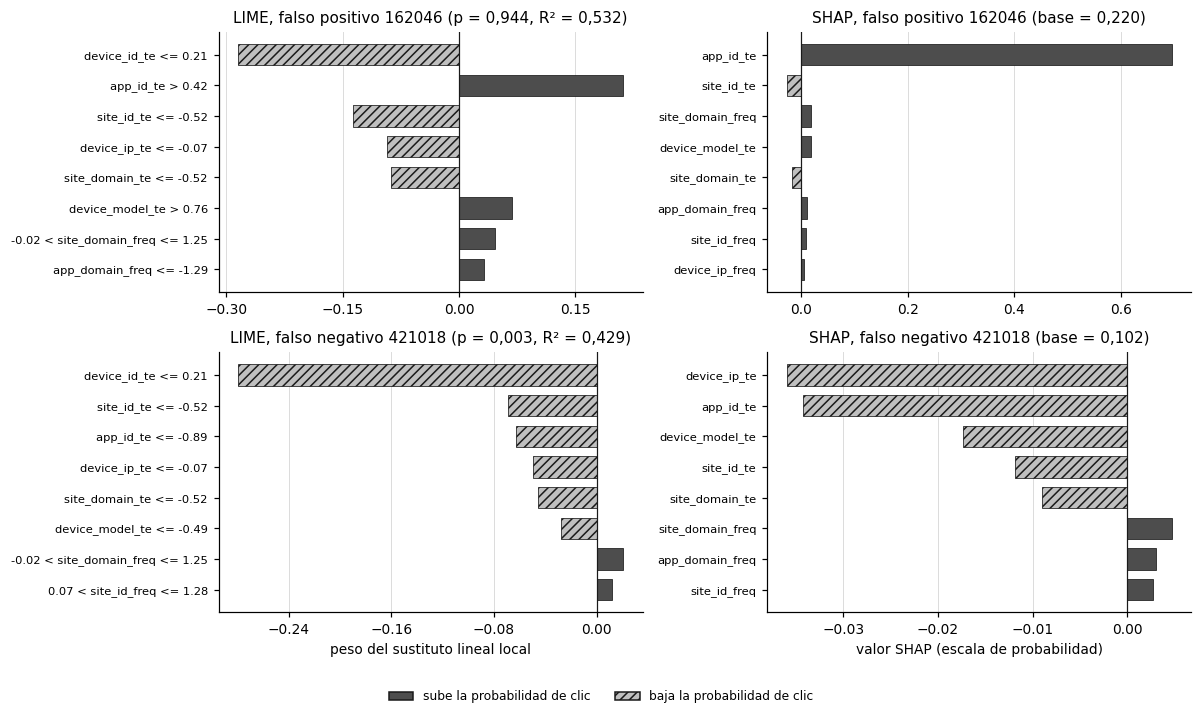

In [4]:
fp_id = int(inst.query("tipo_error == 'FP'")["p_pred"].idxmax())
fn_id = int(inst.query("tipo_error == 'FN'")["p_pred"].idxmin())
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
for fila, (iid, nombre) in enumerate(((fp_id, "falso positivo"), (fn_id, "falso negativo"))):
    r = lime.query("indice_instancia == @iid and seed == 13").iloc[0]
    cond, pesos = json.loads(r["condiciones"]), json.loads(r["pesos"])
    barras(axes[fila, 0], cond, pesos, f"LIME, {nombre} {iid} (p = {es(r['p_pred'], 3)}, R² = {es(r['fidelidad_r2'], 3)})")
    s = shp.query("indice_instancia == @iid").iloc[0]
    top = sorted(FEATS, key=lambda f: abs(s[f]), reverse=True)[:8]
    barras(axes[fila, 1], top, [s[f] for f in top], f"SHAP, {nombre} {iid} (base = {es(s['valor_base'], 3)})")
axes[1, 0].set_xlabel("peso del sustituto lineal local"); axes[1, 1].set_xlabel("valor SHAP (escala de probabilidad)")
fig.legend(handles=LEYENDA, loc="lower center", ncol=2, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

**Interpretación.** En el falso positivo 162046 ($p = 0{,}944$), SHAP atribuye casi todo el exceso sobre el valor base a `app_id_te`, con +0,696 de los 0,724 puntos que separan la predicción de su valor base de 0,220. El resto son aportes menores de `site_id_te` (−0,027), `site_domain_freq` (+0,018) y `device_model_te` (+0,018). LIME también identifica a `app_id_te > 0.42` como la principal condición que sube la probabilidad (+0,212), pero pone primero a `device_id_te <= 0.21`, con un peso negativo de −0,285. En el falso negativo 421018 ($p = 0{,}003$), SHAP reparte la caída entre `device_ip_te` (−0,036), `app_id_te` (−0,034) y `device_model_te` (−0,017), y LIME vuelve a encabezar con `device_id_te <= 0.21` (−0,280), seguido de `site_id_te` y `app_id_te`.

Así mismo, los dos métodos coinciden en la dirección de la variable que más empuja la probabilidad hacia arriba en el falso positivo y en que los target encodings dominan sobre las frecuencias. El error de confianza alta se explica, entonces, porque la aplicación tiene una tasa histórica de clic alta en train y el modelo extrapola esa tasa a una impresión que no la sigue. Discrepan, en cambio, en `device_id_te`: es la primera condición de LIME en ambas instancias y no aparece entre las seis primeras de SHAP. La sección 8.5 muestra que esa condición es la misma en las 12 instancias, lo que obliga a revisar si se trata de una propiedad del modelo o de la forma en que LIME construye el vecindario.

En consecuencia, se decide no interpretar la primera condición de LIME sin el diagnóstico de la sección 8.5 y apoyar la lectura local en las variables donde LIME y SHAP coinciden en signo y orden, como `app_id_te` en los falsos positivos.

## 8.3 Fidelidad y estabilidad

La fidelidad es el $R^2$ ponderado del sustituto lineal sobre las muestras perturbadas, que LIME reporta como `score`: la fracción de la variabilidad de $g_x$ en el vecindario que reproduce $\hat g$. La estabilidad se mide repitiendo LIME con 5 semillas por instancia y calculando el índice de Jaccard entre los conjuntos de las 8 variables principales {cite}`jaccard1912distribution`:

$$J(A, B) = \frac{|A \cap B|}{|A \cup B|}.$$

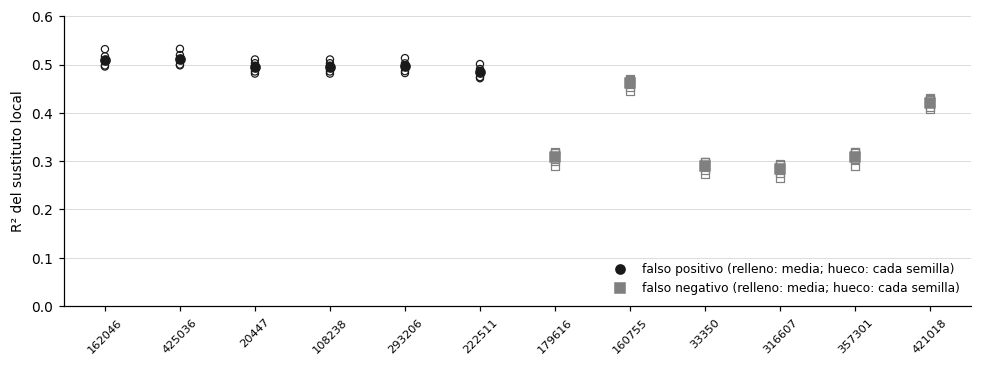

tipo de error,R² medio,DE del R²,R² mínimo,R² máximo,Jaccard medio top-8,Jaccard mínimo
FN,"0,346","0,071","0,265","0,471","0,970","0,778"
FP,"0,499","0,015","0,472","0,533","0,930","0,778"


In [5]:
fig, ax = plt.subplots(figsize=(9, 3.4))
orden = inst.sort_values(["tipo_error", "p_pred"], ascending=[False, False]).index.tolist()
for k, iid in enumerate(orden):
    g = lime.query("indice_instancia == @iid")
    tipo = g["tipo_error"].iloc[0]
    mk, col = ("o", "#1a1a1a") if tipo == "FP" else ("s", "#808080")
    ax.scatter([k] * len(g), g["fidelidad_r2"], marker=mk, facecolor="none", edgecolor=col, s=22, linewidth=0.8)
    ax.scatter([k], [g["fidelidad_r2"].mean()], marker=mk, color=col, s=36, zorder=3)
ax.set_xticks(range(len(orden))); ax.set_xticklabels(orden, rotation=45, fontsize=7.5)
ax.set_ylabel("R² del sustituto local"); ax.set_ylim(0, 0.6)
ax.grid(True, axis="y", color="#d9d9d9", linewidth=0.6); ax.set_axisbelow(True)
for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
ax.legend(handles=[plt.Line2D([], [], marker="o", color="#1a1a1a", linestyle="", label="falso positivo (relleno: media; hueco: cada semilla)"),
                   plt.Line2D([], [], marker="s", color="#808080", linestyle="", label="falso negativo (relleno: media; hueco: cada semilla)")],
          frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
r = lime.groupby("tipo_error")["fidelidad_r2"].agg(["mean", "std", "min", "max"]).reset_index()
e = stab.groupby("tipo_error")[["jaccard_promedio_entre_semillas", "jaccard_min_entre_semillas"]].agg(["mean", "min"]).reset_index()
e.columns = ["tipo_error", "jac_media", "jac_media_min", "jac_min_media", "jac_min_min"]
r = r.merge(e[["tipo_error", "jac_media", "jac_min_min"]], on="tipo_error")
tabla(r.rename(columns={"tipo_error": "tipo de error", "mean": "R² medio", "std": "DE del R²", "min": "R² mínimo",
                        "max": "R² máximo", "jac_media": "Jaccard medio top-8", "jac_min_min": "Jaccard mínimo"}), d=3)

**Interpretación.** El $R^2$ medio es de 0,499 en los falsos positivos (DE 0,015, rango de 0,472 a 0,533) y de 0,346 en los falsos negativos (DE 0,071, rango de 0,265 a 0,471), con un promedio global de 0,423. La estabilidad es alta: el Jaccard medio del top-8 entre semillas es 0,950, con 0,930 en los falsos positivos y 0,970 en los falsos negativos, y 7 de las 12 instancias tienen el mismo top-8 en las 5 semillas. El peor caso, 0,778, equivale a que una de las 8 variables cambie entre dos semillas ($7/9$).

De esta forma, LIME es estable pero solo moderadamente fiel. El sustituto lineal reproduce la mitad de la variabilidad del modelo en el vecindario de los falsos positivos y apenas un tercio en el de los falsos negativos. La diferencia tiene una explicación matemática: LIME ajusta la probabilidad, no el logit, y los falsos negativos están en $p \approx 0{,}005$, donde la sigmoide de salida está saturada. Allí la respuesta del modelo a las perturbaciones es muy asimétrica, porque no puede bajar de 0 y sí puede subir varias décimas, y una recta no la representa bien. Las variables que cambian entre semillas son las de menor peso, como `site_id_freq` y `app_domain_freq`, con pesos absolutos cercanos a 0,02, así que la inestabilidad no afecta el orden de las variables principales.

Por esta razón, lo indicado es reportar siempre el $R^2$ junto con cada explicación de LIME y tratar con más cautela las de los falsos negativos. Una explicación estable no es por eso una explicación correcta: la estabilidad solo dice que el sustituto converge al mismo resultado, no que ese resultado represente bien al modelo.

## 8.4 Sensibilidad al ancho del kernel y al número de muestras

El diseño es un factorial $3 \times 3$ con 3 semillas por celda y las 12 instancias: ancho del kernel de 0,5, 1 y 2 veces el valor por defecto ($\sigma \approx 1{,}40$, $2{,}81$ y $5{,}61$) y 1.000, 5.000 y 10.000 muestras perturbadas. En cada celda se mide la fidelidad, la estabilidad del top-5 entre las 3 semillas y la coincidencia del top-5 con la configuración por defecto (ancho 1x y 5.000 muestras).

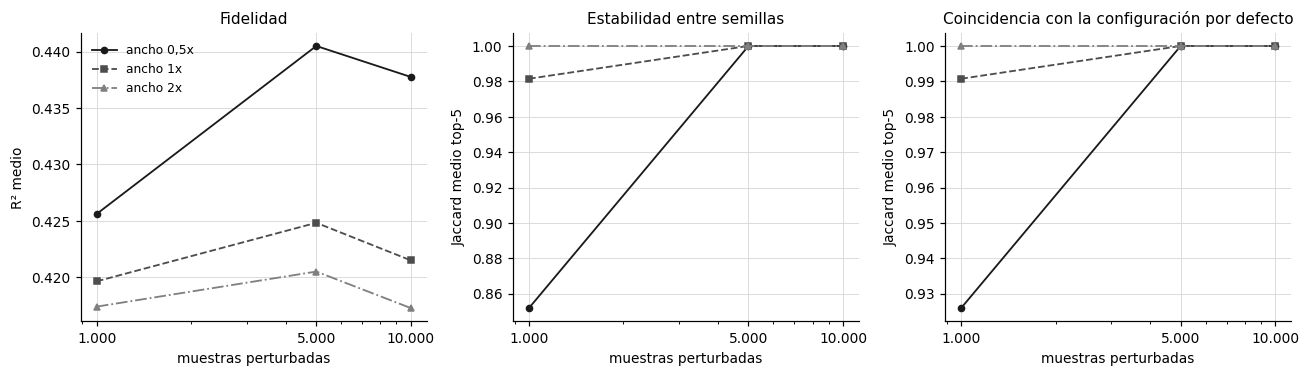

tipo de error,"R² ancho 0,5x",R² ancho 1x,R² ancho 2x
FN,"0,355","0,348","0,346"
FP,"0,514","0,496","0,491"


In [6]:
g = sens.groupby(["ancho_kernel", "num_muestras"])[["fidelidad_r2", "jaccard_entre_semillas", "jaccard_vs_defecto"]].mean().reset_index()
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(12, 3.5))
for (w, st) in zip(["0.5x", "1x", "2x"], series_styles(3)):
    d = g.query("ancho_kernel == @w")
    for ax, c in ((a1, "fidelidad_r2"), (a2, "jaccard_entre_semillas"), (a3, "jaccard_vs_defecto")):
        ax.plot(d["num_muestras"], d[c], label=f"ancho {w.replace('.', ',')}", color=st["color"], linestyle=st["linestyle"],
                marker=st["marker"], markersize=4, linewidth=1.2)
for ax, t_, yl in ((a1, "Fidelidad", "R² medio"), (a2, "Estabilidad entre semillas", "Jaccard medio top-5"),
                   (a3, "Coincidencia con la configuración por defecto", "Jaccard medio top-5")):
    ax.set_xscale("log"); ax.set_xticks([1000, 5000, 10000]); ax.set_xticklabels(["1.000", "5.000", "10.000"])
    ax.set_xlabel("muestras perturbadas"); ax.set_ylabel(yl); ax.set_title(t_, fontsize=10)
    ax.grid(True, color="#d9d9d9", linewidth=0.6); ax.set_axisbelow(True)
    for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
a1.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
t = sens.groupby(["tipo_error", "ancho_kernel"])["fidelidad_r2"].mean().unstack().reset_index()
t.columns.name = None
tabla(t.rename(columns={"tipo_error": "tipo de error", "0.5x": "R² ancho 0,5x", "1x": "R² ancho 1x", "2x": "R² ancho 2x"}), d=3)

**Interpretación.** La fidelidad casi no cambia con el ancho del kernel: va de 0,426 a 0,441 con el ancho de 0,5x, de 0,420 a 0,425 con el de 1x y de 0,417 a 0,420 con el de 2x. Por tipo de error, el kernel estrecho sube el $R^2$ de los falsos positivos de 0,491 a 0,514 y el de los falsos negativos de 0,346 a 0,355. El número de muestras sí importa para la estabilidad: con 1.000 muestras y ancho de 0,5x, el Jaccard entre semillas cae a 0,852 y la coincidencia con la configuración por defecto a 0,926. Desde 5.000 muestras, el top-5 es idéntico entre semillas (Jaccard de 1) y coincide con el de la configuración por defecto en los tres anchos.

Lo anterior indica que el top-5 de LIME es robusto a duplicar o reducir a la mitad el ancho del kernel, y que la fidelidad moderada no se corrige ajustando ese hiperparámetro. Con la discretización, la distancia $D(x,z)$ se calcula sobre el vector binario $z'$, así que el kernel solo cambia cuánto pesan las perturbaciones según cuántas variables salieron del intervalo de la instancia. Un kernel más estrecho concentra el ajuste en las perturbaciones más cercanas y mejora algo el $R^2$, pero con menos muestras efectivas, lo que explica que sea la configuración más inestable cuando solo hay 1.000 muestras. En las explicaciones de la sección 8.3, el top-5 también tiene Jaccard de 1 entre las 5 semillas, así que la estabilidad de 0,950 del top-8 se debe solo a las posiciones 6 a 8.

Con base en esto, se propone mantener la configuración por defecto, ancho de $0{,}75\sqrt p$ y 5.000 muestras, porque está en la zona donde el top-5 ya no depende de la semilla y el costo es de unos 2 segundos por explicación. Usar 1.000 muestras, sobre todo con kernels estrechos, produce explicaciones que cambian con la semilla.

## 8.5 Diagnóstico de la discretización de LIME

En las 12 instancias, falsos positivos y falsos negativos por igual, la condición con mayor peso de LIME es `device_id_te <= 0.21`, con pesos entre −0,38 y −0,16 en las 60 explicaciones (entre −0,24 y −0,31 con la semilla 13), y es la primera en 57 de ellas. Una condición que aparece con el mismo signo y casi el mismo peso en instancias con probabilidades de 0,003 y de 0,94 no puede explicar por qué el modelo las separa. Para entender la causa se revisan dos cosas: cuántos intervalos distintos produce la discretización en cuartiles de cada variable y cuánto cambia la probabilidad cuando solo esa variable se reemplaza por valores de las filas que caen fuera del intervalo de la instancia, que es justo el contraste que hace LIME.

In [7]:
q = disq[["feature", "n_intervalos", "masa_valor_modal", "q25", "q50", "q75"]].sort_values("masa_valor_modal", ascending=False)
tabla(q.rename(columns={"feature": "variable", "n_intervalos": "intervalos de LIME", "masa_valor_modal": "masa del valor modal",
                        "q25": "cuartil 1", "q50": "mediana", "q75": "cuartil 3"}), d=3, enteros=("intervalos de LIME",))
e = dise.groupby(["feature", "tipo_error"])[["fraccion_fuera_intervalo", "cambio_p_medio"]].mean().unstack()
e.columns = [f"{m}_{t}" for m, t in e.columns]
e = e.reset_index()
e = e[e["feature"].str.endswith("_te")].sort_values("cambio_p_medio_FP")
tabla(e.rename(columns={"feature": "variable", "fraccion_fuera_intervalo_FP": "fuera del intervalo (FP)",
                        "cambio_p_medio_FP": "cambio medio de p (FP)", "fraccion_fuera_intervalo_FN": "fuera del intervalo (FN)",
                        "cambio_p_medio_FN": "cambio medio de p (FN)"})[
    ["variable", "fuera del intervalo (FP)", "cambio medio de p (FP)", "fuera del intervalo (FN)", "cambio medio de p (FN)"]], d=4)

variable,intervalos de LIME,masa del valor modal,cuartil 1,mediana,cuartil 3
device_ip_freq,2,"0,862","0,541","0,541","0,541"
device_ip_te,2,"0,862","-0,065","-0,065","-0,065"
device_id_freq,2,"0,845","0,459","0,459","0,459"
device_id_te,2,"0,845","0,209","0,209","0,209"
app_domain_freq,3,"0,555","-1,286","0,671","0,671"
app_domain_te,3,"0,555","-0,763","0,480","0,480"
app_id_freq,3,"0,535","-1,391","0,730","0,730"
app_id_te,3,"0,535","-0,888","0,416","0,416"
site_domain_freq,4,"0,477","-0,955","-0,015","1,247"
site_domain_te,3,"0,477","-0,518","-0,518","0,386"


variable,fuera del intervalo (FP),cambio medio de p (FP),fuera del intervalo (FN),cambio medio de p (FN)
app_id_te,"0,8861","-0,7093","0,4936","0,0061"
app_domain_te,"0,6129","-0,0035","0,4916","0,0001"
device_model_te,"0,7561","-0,0025","0,7318","0,0059"
device_ip_te,"0,1030","0,0114","0,1030","0,0120"
site_domain_te,"0,4022","0,0127","0,4022","0,0085"
site_id_te,"0,4133","0,0249","0,4133","0,0165"
device_id_te,"0,0026","0,0298","0,0026","0,2075"


**Interpretación.** La discretización en cuartiles colapsa en las variables con un valor dominante. En `device_id_te` y `device_ip_te` los tres cuartiles coinciden, porque el valor modal concentra el 84,6 % y el 86,2 % de las filas, y LIME solo forma dos intervalos. En `device_id_te`, el intervalo de las 12 instancias (`<= 0.21`) contiene el 99,74 % de las filas, así que solo el 0,26 % cae fuera. Cuando únicamente esa variable se reemplaza por valores de esas filas, la probabilidad de los falsos negativos sube de 0,006 a 0,213 en promedio (+0,208) y la de los falsos positivos sube 0,030. `app_id_te`, en cambio, está fuera del intervalo de los falsos positivos en el 88,6 % de las filas, y al reemplazarla la probabilidad de esos falsos positivos cae de 0,912 a 0,202 (−0,709).

Esto quiere decir que el peso de `device_id_te` en LIME no describe el vecindario de la instancia, sino un evento raro. Con 5.000 perturbaciones, se esperan $5.000 \times 0{,}0026 \approx 13$ muestras fuera del intervalo, y el sustituto lineal estima con ellas un coeficiente grande porque en esas pocas muestras la probabilidad cambia mucho: son impresiones de dispositivos con tasa histórica de clic alta. Como el efecto es grande y casi el mismo para cualquier instancia del intervalo modal, LIME lo pone primero de forma estable en las 12 instancias, lo que muestra de nuevo que la estabilidad no garantiza la fidelidad. SHAP, con un fondo de 100 filas, espera $100 \times 0{,}0026 = 0{,}26$ filas fuera de ese intervalo, así que casi nunca contrasta la instancia con otro dispositivo, y por eso el valor SHAP medio de `device_id_te` es de 0,0052. Los dos métodos son coherentes con su distribución de referencia, pero responden preguntas distintas. El caso de `app_id_te` es el contrario: el contraste de LIME, el valor SHAP de +0,669 en los falsos positivos y la caída de 0,709 al reemplazarla apuntan a lo mismo, y es la explicación sólida de esos errores.

Por tanto, corresponde reportar, junto con cada peso de LIME, la fracción de la muestra de referencia que cae fuera del intervalo de la instancia, y no interpretar los pesos estimados con menos de unas decenas de muestras perturbadas. En un trabajo posterior, la discretización por cuartiles debería reemplazarse por perturbaciones continuas (`discretize_continuous=False`) o excluir las variables con cuartiles colapsados. Aquí se reporta el resultado sin corregir, porque el objetivo del capítulo es evaluar si LIME es fiel con su configuración estándar, y este es uno de sus modos de falla.

## 8.6 Contraste con SHAP y con la importancia por permutación

SHAP reparte la diferencia entre la predicción y el valor base según los valores de Shapley, que promedian la contribución marginal de cada variable sobre todos los órdenes posibles de entrada {cite}`lundberg2017unified`:

$$\phi_j = \sum_{S \subseteq F \setminus \{j\}} \frac{|S|!\,(|F|-|S|-1)!}{|F|!}\,\Big[v(S \cup \{j\}) - v(S)\Big], \qquad \sum_{j} \phi_j = g_x(\mathbf d_x) - \mathbb E\big[g_x(\mathbf d)\big].$$

Se usa `PermutationExplainer` con un fondo de 100 filas de la muestra de prueba, enmascaramiento independiente y hasta 1.000 evaluaciones por instancia. La propiedad de eficiencia se cumple: la máxima diferencia entre $\sum_j \phi_j + \text{base}$ y la predicción en las 12 instancias es de $4{,}7 \times 10^{-11}$. La importancia por permutación mide la caída del AUC al permutar cada variable en 200.000 filas del día 30, con 5 repeticiones; el IC 95 % usa $t_{0{,}975;\,4} = 2{,}776$.

In [8]:
p = perm[["feature", "caida_auc_media", "caida_auc_de"]].copy()
p["IC 95 % inferior"] = p["caida_auc_media"] - 2.776 * p["caida_auc_de"] / np.sqrt(5)
p["IC 95 % superior"] = p["caida_auc_media"] + 2.776 * p["caida_auc_de"] / np.sqrt(5)
print(f"AUC sin permutar en las 200.000 filas: {es(perm['auc_base'].iloc[0], 4)}")
tabla(p.rename(columns={"feature": "variable", "caida_auc_media": "caída media del AUC", "caida_auc_de": "DE (5 repeticiones)"}), d=4)

AUC sin permutar en las 200.000 filas: 0,7326


variable,caída media del AUC,DE (5 repeticiones),IC 95 % inferior,IC 95 % superior
app_id_te,"0,0925","0,0008","0,0915","0,0935"
site_id_te,"0,0467","0,0007","0,0459","0,0476"
site_domain_te,"0,0230","0,0004","0,0225","0,0235"
device_model_te,"0,0142","0,0005","0,0136","0,0148"
site_domain_freq,"0,0061","0,0002","0,0058","0,0064"
device_ip_te,"0,0059","0,0001","0,0057","0,0060"
device_ip_freq,"0,0040","0,0003","0,0036","0,0044"
device_id_te,"0,0031","0,0001","0,0030","0,0033"
site_id_freq,"0,0022","0,0001","0,0021","0,0023"
device_id_freq,"0,0017","0,0001","0,0016","0,0019"


**Interpretación.** Sobre un AUC de 0,7326, permutar `app_id_te` lo reduce en 0,0925, `site_id_te` en 0,0467, `site_domain_te` en 0,0230 y `device_model_te` en 0,0142. Las 10 variables restantes, entre ellas `device_id_te` (0,0031) y todas las frecuencias, reducen el AUC menos de 0,007 cada una. Las desviaciones entre repeticiones son menores de 0,001, así que los intervalos no se cruzan entre las cuatro primeras variables.

Es decir, la capacidad de ordenar del MLP depende sobre todo de la tasa histórica de clic de la aplicación y del sitio. Las frecuencias aportan poco una vez que el target encoding y el hashing ya identifican la categoría, lo que coincide con la ablación de la sección 9.3: la codificación solo por frecuencia es la peor de todas.

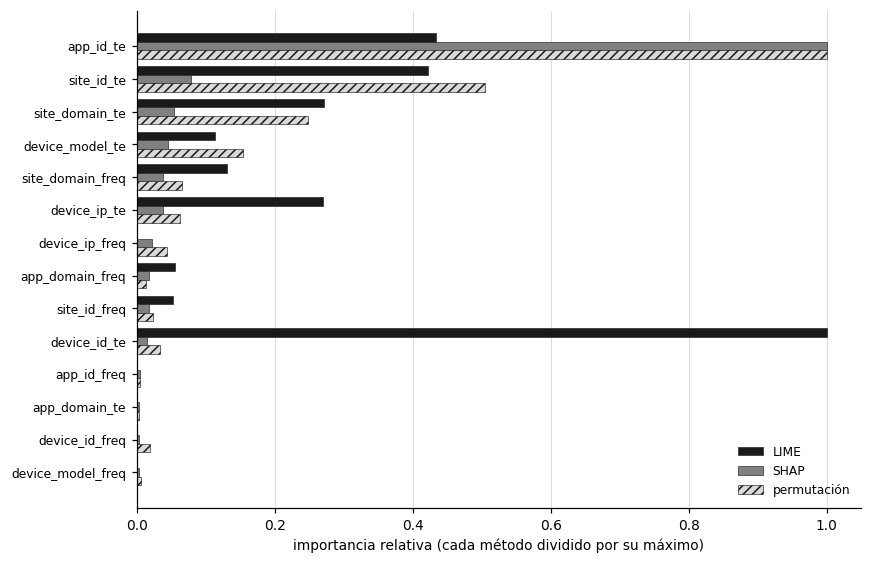

par,rho de Spearman,p
LIME frente a SHAP,"0,7170","0,0039"
LIME frente a permutación,"0,7620","0,0015"
SHAP frente a permutación,"0,9253","0,0000"


tipo de error,Jaccard medio LIME–SHAP (top-5),mínimo,máximo
FN,"0,587","0,429","0,667"
FP,"0,518","0,250","0,667"


In [9]:
lime_abs = {}
for _, r in lime.iterrows():
    for f, w in zip(json.loads(r["top_features"]), json.loads(r["pesos"])):
        lime_abs.setdefault(f, []).append(abs(w))
n_exp = len(lime)
g = pd.DataFrame({"variable": FEATS})
g["LIME"] = g["variable"].map(lambda f: np.sum(lime_abs.get(f, [0])) / n_exp)
g["SHAP"] = g["variable"].map(lambda f: shp[f].abs().mean())
g["permutación"] = g["variable"].map(perm.set_index("feature")["caida_auc_media"])
g = g.sort_values("SHAP", ascending=True)
fig, ax = plt.subplots(figsize=(8, 5.2))
y = np.arange(len(g)); h = 0.26
for k, (c, col, hat) in enumerate((("LIME", "#1a1a1a", ""), ("SHAP", "#808080", ""), ("permutación", "#d9d9d9", "////"))):
    ax.barh(y + (1 - k) * h, g[c] / g[c].max(), height=h, color=col, hatch=hat, edgecolor="#1a1a1a", linewidth=0.4, label=c)
ax.set_yticks(y); ax.set_yticklabels(g["variable"], fontsize=8)
ax.set_xlabel("importancia relativa (cada método dividido por su máximo)")
ejes(ax, ""); ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
from scipy.stats import spearmanr
rho = pd.DataFrame([{"par": a + " frente a " + b, "rho de Spearman": spearmanr(g[a], g[b]).statistic,
                     "p": spearmanr(g[a], g[b]).pvalue} for a, b in (("LIME", "SHAP"), ("LIME", "permutación"), ("SHAP", "permutación"))])
tabla(rho, d=4)
t = agr.groupby("tipo_error")["jaccard_lime_vs_shap_media"].agg(["mean", "min", "max"]).reset_index()
tabla(t.rename(columns={"tipo_error": "tipo de error", "mean": "Jaccard medio LIME–SHAP (top-5)", "min": "mínimo", "max": "máximo"}), d=3)

**Interpretación.** SHAP y la importancia por permutación coinciden casi por completo, con un $\rho$ de Spearman de 0,925 entre sus rankings de las 14 variables, y ambos ponen primero a `app_id_te`, con un valor SHAP absoluto medio de 0,343, más de diez veces el de la segunda variable, `site_id_te` (0,027). LIME se parece menos a los otros dos métodos ($\rho$ de 0,722 con SHAP y de 0,766 con la permutación), y la razón principal es `device_id_te`: es la variable más pesada de LIME y ocupa el lugar 10 en SHAP (0,0052) y el 8 en la permutación. En el top-5 de cada instancia, el Jaccard medio entre LIME y SHAP es de 0,553, con 0,518 en los falsos positivos y 0,587 en los falsos negativos, y va de 0,25 a 0,67; con conjuntos de 5 variables, $J = k/(10-k)$ si comparten $k$, así que LIME y SHAP comparten entre 2 y 4 variables por instancia y 3,5 en promedio.

Hay que tener en cuenta que los tres métodos responden preguntas distintas. La permutación mide la importancia global para el AUC, SHAP atribuye una predicción concreta frente a un fondo y LIME ajusta una recta en un vecindario construido con intervalos. La coherencia entre SHAP y la permutación, que son conceptualmente distintos pero coinciden, da confianza en que `app_id_te`, `site_id_te` y `site_domain_te` son las variables que realmente usa el modelo. Los valores de *p* de Spearman, todos por debajo de 0,004, se reportan como descriptivos: con 14 variables y empates en los ceros de LIME, no corresponden a un contraste planificado.

De ahí que se opte por SHAP como método de referencia para la atribución local de este modelo y por la permutación para la importancia global, y que LIME se use como evidencia complementaria, siempre acompañado de su $R^2$ y del diagnóstico de discretización.

## 8.7 Respuesta a la pregunta P4

¿Son las explicaciones de LIME estables y fieles al modelo? La respuesta es que son estables pero no plenamente fieles. Son estables porque, con 5.000 muestras, el top-5 es idéntico entre semillas y no cambia al reducir a la mitad o duplicar el ancho del kernel, y el top-8 tiene un Jaccard medio de 0,950. No son plenamente fieles por tres razones medidas: el sustituto reproduce el 42 % de la variabilidad local del modelo en promedio y solo el 35 % en los falsos negativos, la condición principal en las 12 instancias es un efecto de la discretización y no de la instancia (sección 8.5), y comparte en promedio 3,5 de sus 5 variables principales con SHAP.

En síntesis, LIME aporta una explicación rápida, legible como reglas y reproducible si se fija el número de muestras. Lo que no puede garantizar es que esas reglas describan el modelo: la estabilidad mide la convergencia del procedimiento, no su exactitud, y la fidelidad depende de la forma del modelo en el vecindario y de cómo se discretizan las variables. La comparación con SHAP, que cumple la propiedad de eficiencia hasta $10^{-11}$ y coincide con la importancia por permutación, es la que permite detectar cuándo LIME se desvía.